This notebook combines the data from transfermarket in order to create a graph structure with nodes as clubs, directed weighted edges of transfers between clubs. 

**Important:** The goal is to produce a dataset for all players, a dataset for players below 30 and a dataset for players above 30. 

In [5]:
import pandas as pd
import numpy as np

In [6]:
from pathlib import Path

data_dir = next(path for path in (
    Path('../data/transfermarkt-datasets'),
    Path('data/transfermarkt-datasets'),
    Path('pnas_report/data/transfermarkt-datasets'),
) if path.is_dir())
transfers = pd.read_csv(data_dir / 'transfers.csv.gz')
transfers.head()

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur,player_name
0,467994,2030-06-30,25/26,5621,749,Reggiana,FC Empoli,0.0,700000.0,Luca Belardinelli
1,645842,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,150000.0,Chan-gi An
2,677470,2028-02-02,27/28,6505,3535,Gimcheon Sangmu,Ulsan HD,0.0,400000.0,Yool Heo
3,709155,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,325000.0,Jae-hyeok Oh
4,728133,2028-02-02,27/28,6505,35759,Gimcheon Sangmu,Bucheon FC,0.0,175000.0,Sang-hyeok Lee


In [7]:
players = pd.read_csv(data_dir / 'players.csv.gz')
players.head()

,player_id,first_name,last_name,name,last_season,current_club_id,player_code,country_of_birth,city_of_birth,country_of_citizenship,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur,highest_market_value_in_eur
0,10,Miroslav,Klose,Miroslav Klose,2015,398,miroslav-klose,Poland,Opole,Germany,...,ASBW Sport Marketing,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/miroslav-klose...,IT1,Società Sportiva Lazio S.p.A.,1000000.0,30000000.0
1,26,Roman,Weidenfeller,Roman Weidenfeller,2017,16,roman-weidenfeller,Germany,Diez,Germany,...,Neubauer 13 GmbH,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/roman-weidenfe...,L1,Borussia Dortmund,750000.0,8000000.0
2,65,Dimitar,Berbatov,Dimitar Berbatov,2015,1091,dimitar-berbatov,Bulgaria,Blagoevgrad,Bulgaria,...,CSKA-AS-23 Ltd.,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/dimitar-berbat...,GR1,Panthessalonikios Athlitikos Omilos Konstantin...,1000000.0,34500000.0
3,77,NaN,Lúcio,Lúcio,2012,506,lucio,Brazil,Brasília,Brazil,...,NaN,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/lucio/profil/s...,IT1,Juventus FC,200000.0,24500000.0
4,80,Tom,Starke,Tom Starke,2017,27,tom-starke,East Germany (GDR),Freital,Germany,...,IFM,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/tom-starke/pro...,L1,Bayern Munich,100000.0,3000000.0


In [8]:
transfers_with_players = transfers.merge(
    players,
    on='player_id',
    how='inner',
    suffixes=('_transfer', '_player'),
)
transfers_with_players.head()

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur_transfer,player_name,...,agent_name,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur_player,highest_market_value_in_eur
0,467994,2030-06-30,25/26,5621,749,Reggiana,FC Empoli,0.0,700000.0,Luca Belardinelli,...,NaN,https://img.a.transfermarkt.technology/portrai...,1.0,0.0,NaN,https://www.transfermarkt.co.uk/luca-belardine...,IT1,FC Empoli,700000.0,2600000.0
1,645842,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,150000.0,Chan-gi An,...,BG SPORTS MANAGEMENT,https://img.a.transfermarkt.technology/portrai...,2.0,0.0,NaN,https://www.transfermarkt.co.uk/chan-gi-an/pro...,RSK1,Jeju SK Football Club,150000.0,150000.0
2,677470,2028-02-02,27/28,6505,3535,Gimcheon Sangmu,Ulsan HD,0.0,400000.0,Yool Heo,...,The Roots,https://img.a.transfermarkt.technology/portrai...,3.0,0.0,NaN,https://www.transfermarkt.co.uk/yool-heo/profi...,RSK1,Ulsan Hyundai Football Club,400000.0,600000.0
3,709155,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,325000.0,Jae-hyeok Oh,...,FS Corporation,https://img.a.transfermarkt.technology/portrai...,4.0,1.0,NaN,https://www.transfermarkt.co.uk/jae-hyeok-oh/p...,RSK1,Jeju SK Football Club,325000.0,350000.0
4,728133,2028-02-02,27/28,6505,35759,Gimcheon Sangmu,Bucheon FC,0.0,175000.0,Sang-hyeok Lee,...,LITY SPORTS,https://img.a.transfermarkt.technology/portrai...,1.0,0.0,NaN,https://www.transfermarkt.co.uk/sang-hyeok-lee...,RSK1,Bucheon Football Club 1995,175000.0,250000.0


In [9]:
transfers_with_players.columns.tolist

<bound method IndexOpsMixin.tolist of Index(['player_id', 'transfer_date', 'transfer_season', 'from_club_id',
       'to_club_id', 'from_club_name', 'to_club_name', 'transfer_fee',
       'market_value_in_eur_transfer', 'player_name', 'first_name',
       'last_name', 'name', 'last_season', 'current_club_id', 'player_code',
       'country_of_birth', 'city_of_birth', 'country_of_citizenship',
       'date_of_birth', 'sub_position', 'position', 'foot', 'height_in_cm',
       'contract_expiration_date', 'agent_name', 'image_url',
       'international_caps', 'international_goals', 'current_national_team_id',
       'url', 'current_club_domestic_competition_id', 'current_club_name',
       'market_value_in_eur_player', 'highest_market_value_in_eur'],
      dtype='str')>

In [10]:
transfer_date = pd.to_datetime(transfers_with_players['transfer_date'])
birth_date = pd.to_datetime(transfers_with_players['date_of_birth'])
transfers_with_players['age_when_transferred'] = (
    transfer_date.dt.year - birth_date.dt.year
    - (
        (transfer_date.dt.month < birth_date.dt.month)
        | ((transfer_date.dt.month == birth_date.dt.month) & (transfer_date.dt.day < birth_date.dt.day))
    )
).astype('Int64')

In [11]:
transfers_with_players

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur_transfer,player_name,...,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur_player,highest_market_value_in_eur,age_when_transferred
0,467994,2030-06-30,25/26,5621,749,Reggiana,FC Empoli,0.0,700000.0,Luca Belardinelli,...,https://img.a.transfermarkt.technology/portrai...,1.0,0.0,NaN,https://www.transfermarkt.co.uk/luca-belardine...,IT1,FC Empoli,700000.0,2600000.0,29
1,645842,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,150000.0,Chan-gi An,...,https://img.a.transfermarkt.technology/portrai...,2.0,0.0,NaN,https://www.transfermarkt.co.uk/chan-gi-an/pro...,RSK1,Jeju SK Football Club,150000.0,150000.0,29
2,677470,2028-02-02,27/28,6505,3535,Gimcheon Sangmu,Ulsan HD,0.0,400000.0,Yool Heo,...,https://img.a.transfermarkt.technology/portrai...,3.0,0.0,NaN,https://www.transfermarkt.co.uk/yool-heo/profi...,RSK1,Ulsan Hyundai Football Club,400000.0,600000.0,26
3,709155,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,325000.0,Jae-hyeok Oh,...,https://img.a.transfermarkt.technology/portrai...,4.0,1.0,NaN,https://www.transfermarkt.co.uk/jae-hyeok-oh/p...,RSK1,Jeju SK Football Club,325000.0,350000.0,25
4,728133,2028-02-02,27/28,6505,35759,Gimcheon Sangmu,Bucheon FC,0.0,175000.0,Sang-hyeok Lee,...,https://img.a.transfermarkt.technology/portrai...,1.0,0.0,NaN,https://www.transfermarkt.co.uk/sang-hyeok-lee...,RSK1,Bucheon Football Club 1995,175000.0,250000.0,27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
175160,22141,1994-07-01,94/95,59178,29463,Castellammare,Sorrento Youth,NaN,NaN,Antonio Mirante,...,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/antonio-mirant...,IT1,AC Milan,100000.0,6000000.0,10
175161,33829,1994-07-01,94/95,58405,53957,FC Penafiel You,Sporting Yth.,NaN,NaN,José Fonte,...,https://img.a.transfermarkt.technology/portrai...,50.0,1.0,NaN,https://www.transfermarkt.co.uk/jose-fonte/pro...,PO1,Casa Pia AC,100000.0,7000000.0,10
175162,40680,1994-07-01,94/95,47320,47318,Lichtenw. Yth.,Schornbach Yth.,0.0,NaN,Sven Ulreich,...,https://img.a.transfermarkt.technology/portrai...,0.0,0.0,NaN,https://www.transfermarkt.co.uk/sven-ulreich/p...,L1,Bayern Munich,500000.0,6000000.0,5
175163,21101,1993-07-01,93/94,140068,129841,Host.-Her. Yth.,Drnovice Yth.,NaN,NaN,Milan Petrzela,...,https://img.a.transfermarkt.technology/portrai...,19.0,0.0,NaN,https://www.transfermarkt.co.uk/milan-petrzela...,TS1,1.FC Slovacko,10000.0,1700000.0,10


In [12]:
date_range = transfer_date.between('2015-01-01', '2026-01-09')
players_20_plus = transfers_with_players[date_range & (transfers_with_players['age_when_transferred'] >= 20)].copy()
players_30_plus = transfers_with_players[date_range & (transfers_with_players['age_when_transferred'] >= 30)].copy()

In [13]:
players_20_plus['transfer_date'].min(), players_20_plus['transfer_date'].max(), players_30_plus['transfer_date'].min(), players_30_plus['transfer_date'].max()

('2015-01-01', '2026-01-09', '2015-01-28', '2026-01-09')

In [14]:
players_30_plus

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur_transfer,player_name,...,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur_player,highest_market_value_in_eur,age_when_transferred
7149,55291,2026-01-09,25/26,1191,1241,Falkirk,Livingston FC,0.0,50000.0,Scott Arfield,...,https://img.a.transfermarkt.technology/portrai...,19.0,2.0,NaN,https://www.transfermarkt.co.uk/scott-arfield/...,SC1,Falkirk FC,25000.0,3000000.0,37
7150,85291,2026-01-09,25/26,152,20,Samsunspor,Bursaspor,0.0,100000.0,Soner Aydoğdu,...,https://img.a.transfermarkt.technology/portrai...,2.0,0.0,NaN,https://www.transfermarkt.co.uk/soner-aydogdu/...,TR1,Samsunspor,100000.0,4200000.0,35
7151,92572,2026-01-09,25/26,515,2288,Without Club,Swansea,NaN,300000.0,Joel Ward,...,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/joel-ward/prof...,GB1,Crystal Palace,300000.0,5000000.0,36
7152,103890,2026-01-09,25/26,189,184,Boca Juniors,Alianza Lima,0.0,200000.0,Luis Advíncula,...,https://img.a.transfermarkt.technology/portrai...,131.0,2.0,3584.0,https://www.transfermarkt.co.uk/luis-advincula...,NaN,NaN,150000.0,3000000.0,35
7153,139923,2026-01-09,25/26,13379,10090,Cúcuta Dep.,Deportivo Pasto,0.0,150000.0,Matías Pisano,...,https://img.a.transfermarkt.technology/portrai...,0.0,0.0,NaN,https://www.transfermarkt.co.uk/matias-pisano/...,COL1,Asociación Deportivo Pasto,150000.0,3400000.0,34
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147071,15185,2015-06-30,14/15,46,11,Inter,Arsenal,0.0,7500000.0,Lukas Podolski,...,https://img.a.transfermarkt.technology/portrai...,130.0,49.0,NaN,https://www.transfermarkt.co.uk/lukas-podolski...,PL1,Górnik Zabrze,100000.0,23000000.0,30
147074,20137,2015-06-30,14/15,114,6414,Besiktas,Metalist Kharkiv,0.0,7000000.0,José Sosa,...,https://img.a.transfermarkt.technology/portrai...,19.0,1.0,NaN,https://www.transfermarkt.co.uk/jose-sosa/prof...,ARG1,Club Estudiantes de La Plata,50000.0,10000000.0,30
147090,45717,2015-06-30,14/15,3522,276,Spezia Calcio,Hellas Verona,0.0,400000.0,Nenê,...,https://img.a.transfermarkt.technology/portrai...,NaN,NaN,NaN,https://www.transfermarkt.co.uk/nene/profil/sp...,PO1,Avs Futebol,50000.0,6000000.0,31
147579,2989,2015-06-16,14/15,199,614,Corinthians,Flamengo,0.0,5500000.0,Paolo Guerrero,...,https://img.a.transfermarkt.technology/portrai...,129.0,41.0,3584.0,https://www.transfermarkt.co.uk/paolo-guerrero...,NaN,NaN,50000.0,8000000.0,31


In [15]:
cols = ['from_club_id', 'to_club_id', 'from_club_name', 'to_club_name']

unique_transfers = (
    transfers_with_players[cols]
    .drop_duplicates()
    .sort_values(['from_club_name', 'to_club_name'])
)

unique_transfers
#unique_transfers.to_csv(data_dir / 'unique_transfers.csv', index=False)

,from_club_id,to_club_id,from_club_name,to_club_name
139516,78284,32807,'t Zand Youth,Willem II Youth
27156,95970,83839,011 U19,IMT Belgrad U19
103902,95970,54517,011 U19,Vozdovac U19
120499,98680,95970,011 U17,011 U19
92398,98680,93981,011 U17,Lokomotiva U19
...,...,...,...,...
164939,58463,4645,Šumadija 1903,Radnicki 1923
103752,95820,76275,Šumadija U17,Apolon 4 U17
171907,21762,25545,ȘF Gică Popescu,AS Rom Youth
174287,21762,75,ȘF Gică Popescu,Unknown


### Club ID exclusion criteria

The ID list is in `../data/exclusion_criteria.csv`. An ID is listed if **any** observed name for that ID matches a rule below (case insensitive). The next cell removes a transfer pair if either club ID is listed.

| Category | Matching club-name labels |
| --- | --- |
| Ages 15–23 | Separate `U`, `Y`, or `S` plus age, or `Sub-` plus age (for example `U15`, `S17`, `Sub-15`, `U20`, `U21`, `U23`) |
| Bare youth age | Final standalone `15`, `17`, or `19` (for example `Portimonense 15`) |
| Youth aliases | Separate `Youth`, `Yth`, `Yt`, `Jgd`, `Jugend`, or a final `Y`/`Y.` |
| Academy | Separate `Academy`, `Akademia`, or `Akad.` |
| Junior | Separate `Junior`, `Juniors`, or `Jun.` |
| B team | Final `B`, `B Team`, `B-Team`, or `(B)` |
| II team | Final `II`, `II Team`, `II-Team`, or `(II)` |
| 2 team | Final `2` or `-2` |
| Reserve | Separate `Reserve`, `Reserves`, or `Res.` |

This excludes 7,763 IDs and 35,313 of 110,316 unique transfer pairs, leaving 75,003. The full 175,165-row player-transfer table retains 105,644 rows. Bare `18` and `20` endings are omitted because they occur in senior club names; `Junior(s)` can also match senior clubs such as Boca Juniors.

Excluded club IDs: 7,763
Transfer pairs: 110,316 before, 75,003 after
Player transfers: 175,165 before, 105,644 after


,from_club_id,to_club_id,from_club_name,to_club_name
42423,27811,4313,07 Vestur,HB Tórshavn
8472,27811,6170,07 Vestur,KÍ Klaksvík
169185,5225,18850,1. FC Brno,Breclav
168630,5225,58,1. FC Brno,RSC Anderlecht
94533,14559,9572,1. Göppinger SV,Chemie Leipzig
1271,392,515,1.FC Bocholt,Without Club
63027,2086,50,1.FC Bruchsal,Rot Weiss Ahlen
19566,67453,515,1.FC Düren,Without Club
15276,2,3,1.FC K'lautern,1.FC Köln
117866,2,187,1.FC K'lautern,1.FC Magdeburg


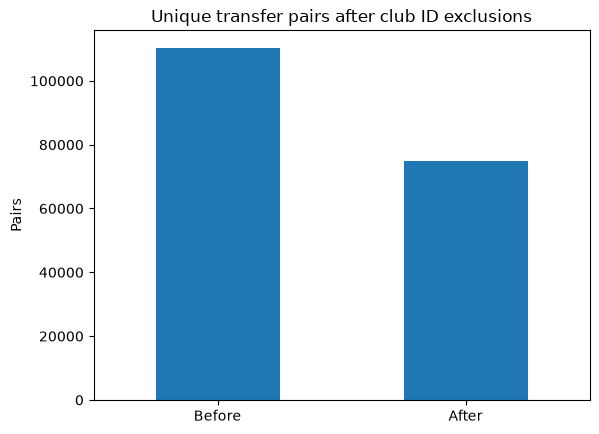

In [16]:
exclusion_ids = set(pd.read_csv(data_dir.parent / 'exclusion_criteria.csv')['club_id'])
cleaned_unique_transfers = unique_transfers[
    ~unique_transfers['from_club_id'].isin(exclusion_ids)
    & ~unique_transfers['to_club_id'].isin(exclusion_ids)
].copy()

cleaned_transfers_with_players = transfers_with_players[
    ~transfers_with_players['from_club_id'].isin(exclusion_ids)
    & ~transfers_with_players['to_club_id'].isin(exclusion_ids)
].copy()

print(f'Excluded club IDs: {len(exclusion_ids):,}')
print(f'Transfer pairs: {len(unique_transfers):,} before, {len(cleaned_unique_transfers):,} after')
print(f'Player transfers: {len(transfers_with_players):,} before, {len(cleaned_transfers_with_players):,} after')
display(cleaned_unique_transfers.head(20))

pd.Series(
    {'Before': len(unique_transfers), 'After': len(cleaned_unique_transfers)}
).plot.bar(title='Unique transfer pairs after club ID exclusions', rot=0, ylabel='Pairs');

In [19]:
cleaned_transfers_with_players.head(2)

,player_id,transfer_date,transfer_season,from_club_id,to_club_id,from_club_name,to_club_name,transfer_fee,market_value_in_eur_transfer,player_name,...,image_url,international_caps,international_goals,current_national_team_id,url,current_club_domestic_competition_id,current_club_name,market_value_in_eur_player,highest_market_value_in_eur,age_when_transferred
0,467994,2030-06-30,25/26,5621,749,Reggiana,FC Empoli,0.0,700000.0,Luca Belardinelli,...,https://img.a.transfermarkt.technology/portrai...,1.0,0.0,NaN,https://www.transfermarkt.co.uk/luca-belardine...,IT1,FC Empoli,700000.0,2600000.0,29
1,645842,2028-02-02,27/28,6505,19684,Gimcheon Sangmu,Jeju SK,0.0,150000.0,Chan-gi An,...,https://img.a.transfermarkt.technology/portrai...,2.0,0.0,NaN,https://www.transfermarkt.co.uk/chan-gi-an/pro...,RSK1,Jeju SK Football Club,150000.0,150000.0,29


In [17]:
cleaned_transfers_with_players.columns.tolist()

['player_id',
 'transfer_date',
 'transfer_season',
 'from_club_id',
 'to_club_id',
 'from_club_name',
 'to_club_name',
 'transfer_fee',
 'market_value_in_eur_transfer',
 'player_name',
 'first_name',
 'last_name',
 'name',
 'last_season',
 'current_club_id',
 'player_code',
 'country_of_birth',
 'city_of_birth',
 'country_of_citizenship',
 'date_of_birth',
 'sub_position',
 'position',
 'foot',
 'height_in_cm',
 'contract_expiration_date',
 'agent_name',
 'image_url',
 'international_caps',
 'international_goals',
 'current_national_team_id',
 'url',
 'current_club_domestic_competition_id',
 'current_club_name',
 'market_value_in_eur_player',
 'highest_market_value_in_eur',
 'age_when_transferred']

In [21]:
reduced_transfers_with_players = cleaned_transfers_with_players.copy()

In [18]:
#cleaned_transfers_with_players.to_csv(data_dir / 'cleaned_transfers_with_players.csv.gz', index=False, compression='gzip')